<a href="https://colab.research.google.com/github/anushka-pulugu/Netflix-Data-Analysis/blob/main/Netflix_Content_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('netflix_titles.csv')

In [ ]:
print(df.head()) #to print the first 6 rows of the dataframe

  show_id     type                  title         director  \
0      s1    Movie   Dick Johnson Is Dead  Kirsten Johnson   
1      s2  TV Show          Blood & Water              NaN   
2      s3  TV Show              Ganglands  Julien Leclercq   
3      s4  TV Show  Jailbirds New Orleans              NaN   
4      s5  TV Show           Kota Factory              NaN   

                                                cast        country  \
0                                                NaN  United States   
1  Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...   South Africa   
2  Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...            NaN   
3                                                NaN            NaN   
4  Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...          India   

           date_added  release_year rating   duration  \
0  September 25, 2021          2020  PG-13     90 min   
1  September 24, 2021          2021  TV-MA  2 Seasons   
2  September 24, 2021        

In [ ]:
print(df.info()) #to print the summary of the dataframe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8154 entries, 0 to 8153
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8154 non-null   object
 1   type          8154 non-null   object
 2   title         8154 non-null   object
 3   director      5636 non-null   object
 4   cast          7407 non-null   object
 5   country       7351 non-null   object
 6   date_added    8145 non-null   object
 7   release_year  8154 non-null   int64 
 8   rating        8150 non-null   object
 9   duration      8150 non-null   object
 10  listed_in     8153 non-null   object
 11  description   8153 non-null   object
dtypes: int64(1), object(11)
memory usage: 764.6+ KB
None


In [ ]:
print(df.isnull().sum()) #to print the number of null values

show_id            0
type               0
title              0
director        2518
cast             747
country          803
date_added         9
release_year       0
rating             4
duration           4
listed_in          1
description        1
dtype: int64


In [ ]:
df = df.drop_duplicates() #to drop duplicates in the dataframe

In [ ]:
df['rating'] = df['rating'].fillna('Not Rated')

In [22]:
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')
df['year_added'] = df['date_added'].dt.year
df['director'] = df['director'].fillna('No Director Listed')
df['cast'] = df['cast'].fillna('No Cast Listed')
df['country'] = df['country'].fillna(df['country'].mode()[0]) # Fill with the most frequent country (modus)

In [23]:
print("--- Movies vs TV Shows ---")
print(df['type'].value_counts())

print("\n--- Top 5 Countries Producing Content ---")
print(df['country'].value_counts().head(5))

print("\n--- Content Additions By Year ---")
print(df['year_added'].value_counts().sort_index())

--- Movies vs TV Shows ---
type
Movie      5597
TV Show    2557
Name: count, dtype: int64

--- Top 5 Countries Producing Content ---
country
United States     3374
India              925
United Kingdom     366
Japan              244
South Korea        189
Name: count, dtype: int64

--- Content Additions By Year ---
year_added
2008.0       2
2009.0       2
2010.0       1
2011.0      13
2012.0       3
2013.0      11
2014.0      22
2015.0      73
2016.0     386
2017.0    1045
2018.0    1485
2019.0    1802
2020.0    1808
2021.0    1492
Name: count, dtype: int64


/tmp/ipykernel_524/720308577.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='type', palette='Set2')


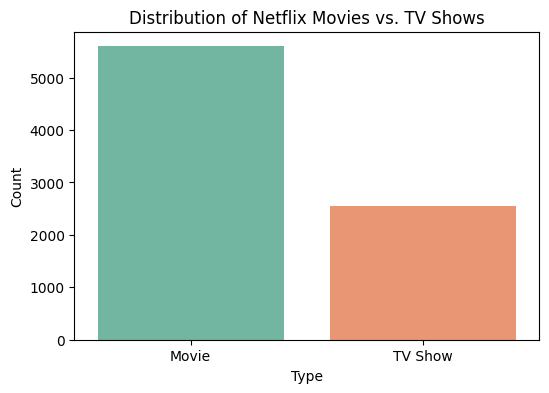

In [24]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='type', palette='Set2')
plt.title('Distribution of Netflix Movies vs. TV Shows')
plt.xlabel('Type')
plt.ylabel('Count')
plt.show()

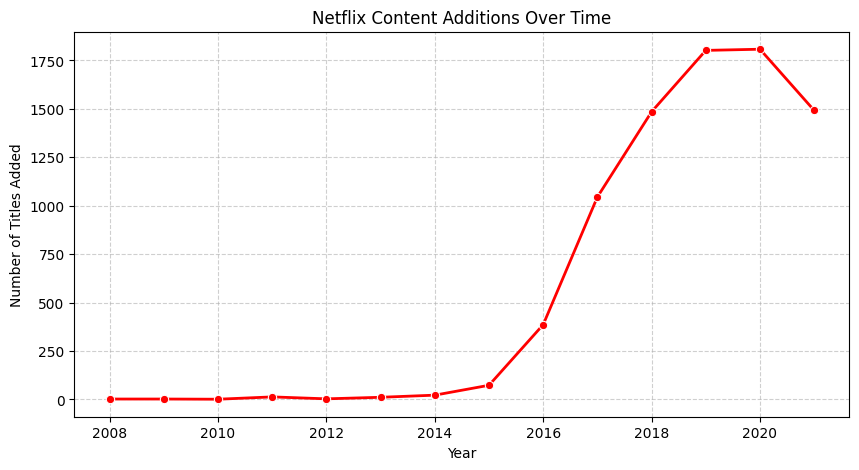

In [25]:
plt.figure(figsize=(10, 5))
yearly_trend = df['year_added'].dropna().value_counts().sort_index()
sns.lineplot(x=yearly_trend.index, y=yearly_trend.values, marker='o', color='red', linewidth=2)
plt.title('Netflix Content Additions Over Time')
plt.xlabel('Year')
plt.ylabel('Number of Titles Added')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

/tmp/ipykernel_524/1242411943.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='rating', order=df['rating'].value_counts().index[:10], palette='viridis')


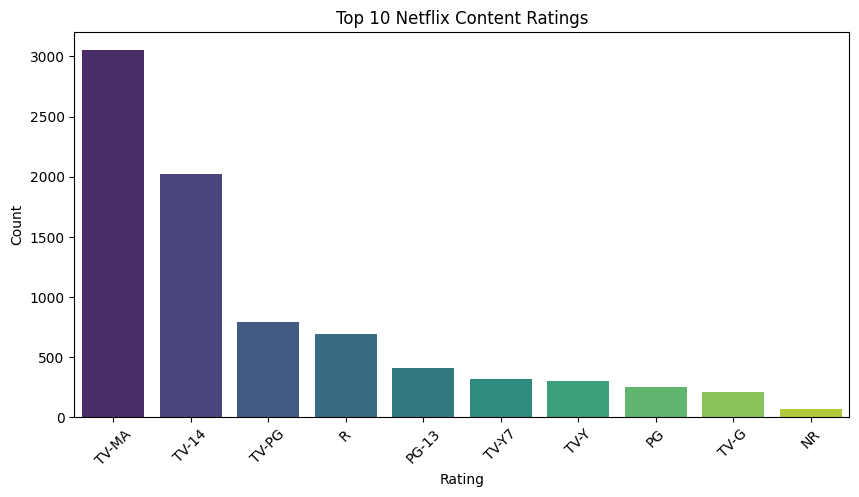

In [26]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='rating', order=df['rating'].value_counts().index[:10], palette='viridis')
plt.title('Top 10 Netflix Content Ratings')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.show()